In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [4]:
df = pd.read_csv("dataset/predict-student-dropout-and-academic-success.csv")

print("Shape:", df.shape)
df.head()

Shape: (4424, 35)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [5]:
print("Missing Values")
print(df.isnull().sum().sum())

print("\nDuplicates")
print(df.duplicated().sum())

print("\nTarget Distribution")
print(df["Target"].value_counts())

Missing Values
0

Duplicates
0

Target Distribution
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [6]:
# First Semester Approval Rate
df["Approval_Rate_1st"] = np.where(
    df["Curricular units 1st sem (enrolled)"] > 0,
    df["Curricular units 1st sem (approved)"] /
    df["Curricular units 1st sem (enrolled)"],
    0
)

# Second Semester Approval Rate
df["Approval_Rate_2nd"] = np.where(
    df["Curricular units 2nd sem (enrolled)"] > 0,
    df["Curricular units 2nd sem (approved)"] /
    df["Curricular units 2nd sem (enrolled)"],
    0
)

# Overall Approval Rate
df["Overall_Approval_Rate"] = np.where(
    (
        df["Curricular units 1st sem (enrolled)"] +
        df["Curricular units 2nd sem (enrolled)"]
    ) > 0,

    (
        df["Curricular units 1st sem (approved)"] +
        df["Curricular units 2nd sem (approved)"]
    ) /

    (
        df["Curricular units 1st sem (enrolled)"] +
        df["Curricular units 2nd sem (enrolled)"]
    ),

    0
)

In [7]:
df["Failed_Units_1st"] = np.maximum(
    df["Curricular units 1st sem (enrolled)"] -
    df["Curricular units 1st sem (approved)"],
    0
)

df["Failed_Units_2nd"] = np.maximum(
    df["Curricular units 2nd sem (enrolled)"] -
    df["Curricular units 2nd sem (approved)"],
    0
)

In [8]:
df["Average_Grade"] = (
    df["Curricular units 1st sem (grade)"] +
    df["Curricular units 2nd sem (grade)"]
) / 2

In [9]:
df["Financial_Risk"] = np.where(
    (df["Debtor"] == 1) |
    (df["Tuition fees up to date"] == 0),
    1,
    0
)

In [10]:
target_mapping = {
    "Graduate": 0,
    "Enrolled": 1,
    "Dropout": 2
}

df["Target"] = df["Target"].map(target_mapping)

In [11]:
X = df.drop("Target", axis=1)

y = df["Target"]

In [12]:
categorical_features = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

In [13]:
numeric_features = [col for col in X.columns
                    if col not in categorical_features]

In [14]:
print("Numeric:", len(numeric_features))
print("Categorical:", len(categorical_features))

Numeric: 24
Categorical: 17


Train-Test Split, Stratified Sampling

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(3539, 41)
(885, 41)


Numeric Pipeline

In [16]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

Categorical Pipeline

In [17]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)


Build Preprocessor

In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Transforming the Dataset

In [19]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Train Shape:", X_train_processed.shape)
print("Test Shape:", X_test_processed.shape)

Train Shape: (3539, 248)
Test Shape: (885, 248)


Saving the Preprocessor

In [20]:
import joblib

joblib.dump(
    preprocessor,
    "dropout_preprocessor.pkl"
)

print("Preprocessor saved.")

Preprocessor saved.


----------------------------------After Preprocessing------------------------------

In [21]:
#Logistic Regression Model
from sklearn.linear_model import LogisticRegression
#Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

import sys

print(sys.executable)

c:\Users\comda\AppData\Local\Python\pythoncore-3.15-64\python.exe


In [22]:
!{sys.executable} -m pip install xgboost


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
from xgboost import XGBClassifier


print("XGBoost installed successfully")

XGBoost installed successfully


----------------------TRAINING OF BASELINE MODELS---------------------------------

In [24]:
#RANDOM FOREST CLASSIFIER

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf.fit(X_train_processed, y_train)

print("Random Forest trained successfully")

Random Forest trained successfully


In [25]:
#LOGISTIC REGRESSION MODEL
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced"
)

lr.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully")

Logistic Regression trained successfully


In [26]:
#XGBOOST CLASSIFIER
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

xgb_model.fit(X_train_processed, y_train)

print("XGBoost trained successfully")

XGBoost trained successfully


--------------------------EVALUATION OF MODELS----------------------------------

In [27]:

from sklearn.metrics import classification_report

In [28]:
#RANDOM FOREST CLASSIFIER EVALUATION
rf_pred = rf.predict(X_test_processed)

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.84      0.84      0.84       442
           1       0.49      0.61      0.54       159
           2       0.87      0.76      0.81       284

    accuracy                           0.77       885
   macro avg       0.73      0.74      0.73       885
weighted avg       0.79      0.77      0.78       885



In [29]:
#LOGISTIC REGRESSION EVALUATION
lr_pred = lr.predict(X_test_processed)

print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.86      0.80      0.83       442
           1       0.45      0.61      0.52       159
           2       0.83      0.75      0.79       284

    accuracy                           0.75       885
   macro avg       0.71      0.72      0.71       885
weighted avg       0.78      0.75      0.76       885



In [30]:
#XGBOOST evaluation
xgb_pred = xgb_model.predict(X_test_processed)

print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.80      0.89      0.85       442
           1       0.61      0.51      0.55       159
           2       0.84      0.78      0.81       284

    accuracy                           0.79       885
   macro avg       0.75      0.73      0.74       885
weighted avg       0.78      0.79      0.78       885



In [31]:
#COMPARISON TABLE

from sklearn.metrics import accuracy_score
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ]
})

results.sort_values(
    by="Accuracy",
    ascending=False
)


,Model,Accuracy
2,XGBoost,0.786441
1,Random Forest,0.771751
0,Logistic Regression,0.751412


-----------------------CONFUSION MATRIX-----------------------

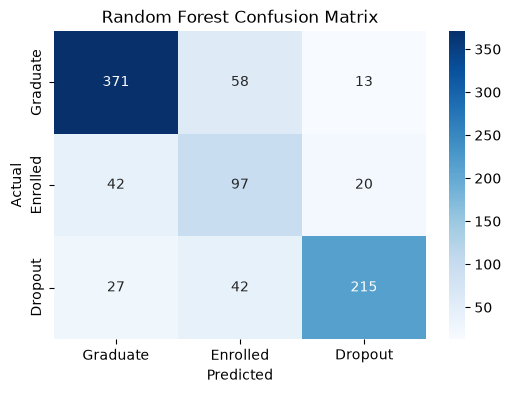

In [54]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

rf_pred = rf.predict(X_test_processed)

cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Graduate","Enrolled","Dropout"],
    yticklabels=["Graduate","Enrolled","Dropout"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

------------------CLASSIFICATION REPORT--------------------------

In [33]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            "Graduate",
            "Enrolled",
            "Dropout"
        ]
    )
)

              precision    recall  f1-score   support

    Graduate       0.84      0.84      0.84       442
    Enrolled       0.49      0.61      0.54       159
     Dropout       0.87      0.76      0.81       284

    accuracy                           0.77       885
   macro avg       0.73      0.74      0.73       885
weighted avg       0.79      0.77      0.78       885



--------------------FEATURE IMPORTANCE----------------
what factor influence dropout risk?


In [34]:
feature_names = preprocessor.get_feature_names_out()

In [35]:
import pandas as pd

importance_df = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance": rf.feature_importances_
    }
)

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

In [36]:
importance_df.head(20)


,Feature,Importance
19,num__Overall_Approval_Rate,0.065403
18,num__Approval_Rate_2nd,0.052478
11,num__Curricular units 2nd sem (approved),0.048947
12,num__Curricular units 2nd sem (grade),0.047713
22,num__Average_Grade,0.045893
21,num__Failed_Units_2nd,0.044931
17,num__Approval_Rate_1st,0.040314
6,num__Curricular units 1st sem (grade),0.035808
5,num__Curricular units 1st sem (approved),0.035769
10,num__Curricular units 2nd sem (evaluations),0.028226


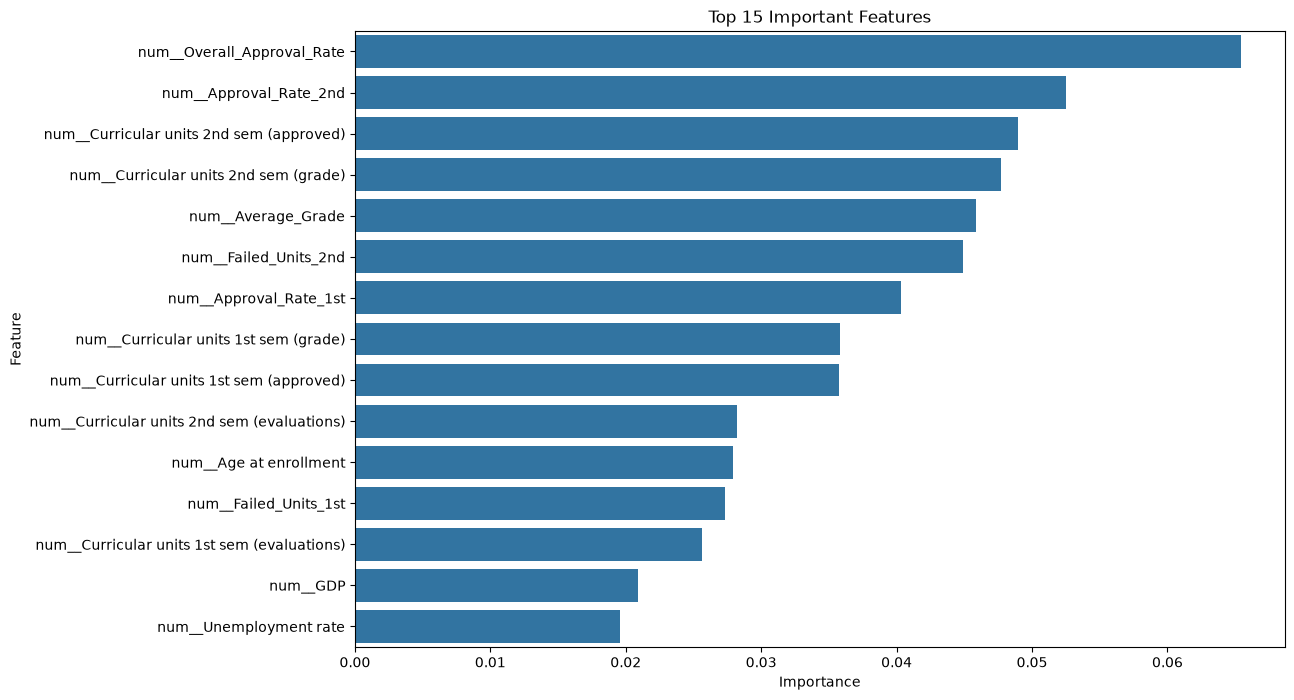

In [37]:
#Visualization of Feature Importance
plt.figure(figsize=(12,8))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.show()

------------------HYPERPARAMETER TUNING-----------------------

In [38]:
#PARAMETER GRID
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'n_estimators': [200,300,500],
    'max_depth': [10,20,30,None],
    'min_samples_split': [2,5,10],
    'min_samples_leaf': [1,2,4],
    'max_features': [
        'sqrt',
        'log2'
    ]
}

In [39]:
#SEARCH

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ),

    param_distributions=param_grid,

    n_iter=20,

    cv=5,

    scoring='f1_weighted',

    verbose=2,

    n_jobs=-1,

    random_state=42
)

In [40]:
#TRAIN
rf_search.fit(
    X_train_processed,
    y_train
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 20, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_weighted'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function w

In [41]:
#BEST PARAMETERS
print(
    rf_search.best_params_
)

print(
    rf_search.best_score_
)

{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}
0.7730578012231248


In [42]:
#Tuned MODEL
best_rf = rf_search.best_estimator_

In [43]:
#Evaluation of tuned model
best_pred = best_rf.predict(
    X_test_processed
)

print(
    classification_report(
        y_test,
        best_pred
    )
)

              precision    recall  f1-score   support

           0       0.85      0.81      0.83       442
           1       0.46      0.65      0.54       159
           2       0.88      0.74      0.80       284

    accuracy                           0.76       885
   macro avg       0.73      0.73      0.72       885
weighted avg       0.79      0.76      0.77       885



---------------------------RISK LEVEL MAPPING-------------------------

In [44]:
#Probability Predictions

probabilities = best_rf.predict_proba(
    X_test_processed
)

In [45]:
#Checking Class Order

print(
    best_rf.classes_
)

[0 1 2]


In [46]:
#Gettin dropout probability

dropout_prob = probabilities[:,2]

In [47]:
#Risk Mapping Function

def risk_level(prob):

    if prob < 0.40:
        return "Low Risk"

    elif prob < 0.70:
        return "Medium Risk"

    else:
        return "High Risk"

In [48]:
#Applying risk mapping function to dropout probabilities

risk_labels = [
    risk_level(p)
    for p in dropout_prob
]

In [49]:
risk_df = pd.DataFrame(
    {
        "Actual": y_test.values,
        "Dropout_Probability": dropout_prob,
        "Risk_Level": risk_labels
    }
)

risk_df.head()

,Actual,Dropout_Probability,Risk_Level
0,0,0.101562,Low Risk
1,0,0.086321,Low Risk
2,2,0.890783,High Risk
3,0,0.099034,Low Risk
4,0,0.033088,Low Risk


In [53]:
#rf
print(classification_report(y_test, rf_pred))
#xgb
print(classification_report(y_test, xgb_pred))
#lr
print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.84      0.84      0.84       442
           1       0.49      0.61      0.54       159
           2       0.87      0.76      0.81       284

    accuracy                           0.77       885
   macro avg       0.73      0.74      0.73       885
weighted avg       0.79      0.77      0.78       885

              precision    recall  f1-score   support

           0       0.80      0.89      0.85       442
           1       0.61      0.51      0.55       159
           2       0.84      0.78      0.81       284

    accuracy                           0.79       885
   macro avg       0.75      0.73      0.74       885
weighted avg       0.78      0.79      0.78       885

              precision    recall  f1-score   support

           0       0.86      0.80      0.83       442
           1       0.45      0.61      0.52       159
           2       0.83      0.75      0.79       284

    accuracy        